# 01 Embedding, kernels y QSVM

Del dato clásico al estado cuántico, del estado a una medida de distancia (kernel) y del kernel a un clasificador (QSVM con iris).

Referencias: handbook ([feature maps](https://iraitzm.github.io/qc-handbook/es/parts/qml/featuremaps.html), [kernels](https://iraitzm.github.io/qc-handbook/es/parts/qml/kernels.html), [QSVM](https://iraitzm.github.io/qc-handbook/es/parts/qml/svm.html)) y `1.3-QML` de la [QML DPG 2026](https://github.com/IraitzM/qml-dpg-2026).


In [1]:
!pip install -q squlearn qiskit-machine-learning qiskit-aer scikit-learn matplotlib pennylane pylatexenc



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


## 1. Tres formas de meter números en qubits

Base (binario a base computacional), ángulo (dato como rotación) y amplitud (vector normalizado como amplitudes). El embedding **es** parte del modelo.


In [2]:
import pennylane as qml
import pennylane.numpy as np

dev = qml.device('default.qubit', wires=2)

@qml.qnode(dev)
def angulo(x):
    qml.AngleEmbedding(features=x, wires=range(2), rotation='Z')
    return qml.state()

x = [0.4, 1.2]  # 2 datos -> 2 qubits en angulo
print('ángulo:  ', np.round(angulo(x), 3))

ángulo:   [0.697-0.717j 0.   +0.j    0.   +0.j    0.   +0.j   ]


In [3]:
@qml.qnode(dev)
def amplitud(x):
    qml.AmplitudeEmbedding(features=x, wires=range(2), normalize=True)
    return qml.state()

# Amplitud: 2 qubits sostienen 2^2 = 4 valores (normalizados)
x4 = [0.4, 1.2, 0.5, 0.9]
print('amplitud:', np.round(amplitud(x4), 3))

amplitud: [0.245+0.j 0.736+0.j 0.307+0.j 0.552+0.j]


## 2. Datos: iris fácil (setosa vs versicolor)

Dos primeras clases, dos primeras variables. Primero mirar los datos, como siempre.


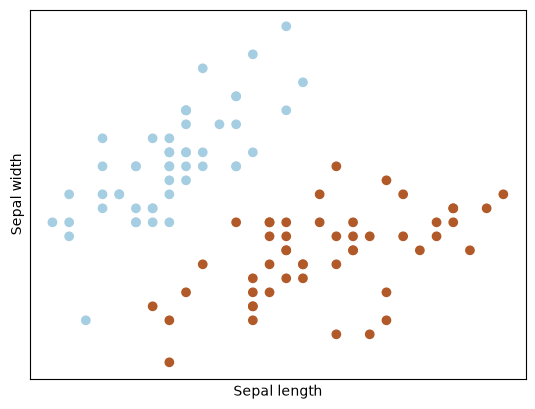

In [4]:
import matplotlib.pyplot as plt
from sklearn import datasets

iris = datasets.load_iris()
X = iris.data[:100, :2]
Y = iris.target[:100]

plt.scatter(X[:, 0], X[:, 1], c=Y, cmap=plt.cm.Paired)
plt.xlabel('Sepal length'); plt.ylabel('Sepal width')
plt.xticks(()); plt.yticks(()); plt.show()


## 3. Split honesto y escalado

El embedding en ángulo vive en $[0, 2\pi]$: escalar a $(-0.9, 0.9)$ no es opcional, es parte del embedding.


In [5]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.33, random_state=42)
scaler = MinMaxScaler((-0.9, 0.9))
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


## 4. Mapa Z + fidelity kernel (compute-uncompute)

$k(x_i,x_j) = \langle 0|\Psi^\dagger(x_i)\Psi(x_j)|0\rangle$: aplicar un mapa y deshacer el otro; contar $|0\rangle^n$ mide el solapamiento.


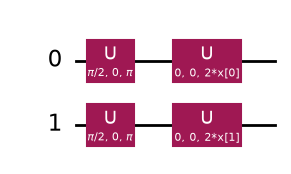

In [ ]:
from qiskit.circuit.library import z_feature_map

fmap = z_feature_map(X_train.shape[1], reps=1)
fmap.decompose().draw('mpl')

In [ ]:
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_algorithms.state_fidelities import ComputeUncompute
from qiskit.primitives import StatevectorSampler

import numpy as np
fidelity = ComputeUncompute(sampler=StatevectorSampler())
kernel = FidelityQuantumKernel(feature_map=fmap, fidelity=fidelity)
def kval(a, b):
    return float(np.asarray(kernel.evaluate(a, b)).flat[0])

print('mismo punto:', kval(X_train[0], X_train[0]))
print('puntos distintos:', kval(X_train[1], X_train[0]))

mismo punto: 1.0
puntos distintos: 0.3349609375


## 5. ¿El kernel ve las clases? Target alignment

$TA(K) = \sum_{ij}K_{ij}y_iy_j / \sqrt{\sum K_{ij}^2 \sum y_i^2y_j^2}$. 

Alto $\implies$ entrenar merece la pena.

In [8]:
import numpy as np

def target_alignment(kernel, X, y_labels):
    kmatrix = kernel.evaluate(X)
    n1 = np.count_nonzero(np.array(y_labels) == 1)
    n0 = len(y_labels) - n1
    ynorm = np.array([y / n1 if y == 1 else y / n0 for y in y_labels])
    T = np.outer(ynorm, ynorm)
    return float(np.sum(kmatrix * T) / np.sqrt(np.sum(kmatrix**2) * np.sum(T**2)))

print('TA train:', round(target_alignment(kernel, X_train, y_train), 3))
print('TA test: ', round(target_alignment(kernel, X_test, y_test), 3))

TA train: 0.608
TA test:  0.503


## 6. QSVC: kernel cuántico + SVC clásico

Lo cuántico produce distancias; `SVC` pone el hiperplano.


In [9]:
from qiskit_machine_learning.algorithms import QSVC

qsvc = QSVC(quantum_kernel=kernel)
qsvc.fit(X_train, y_train)
print('score:', round(qsvc.score(X_test, y_test), 3))

score: 1.0


¿Qué características cuánticas nos aporta el embedding elegido?

## 7. Caso difícil: versicolor vs virginica

Mismo pipeline, clases solapadas. Comparad $TA$ y acierto: aquí el mapa simple sufre.


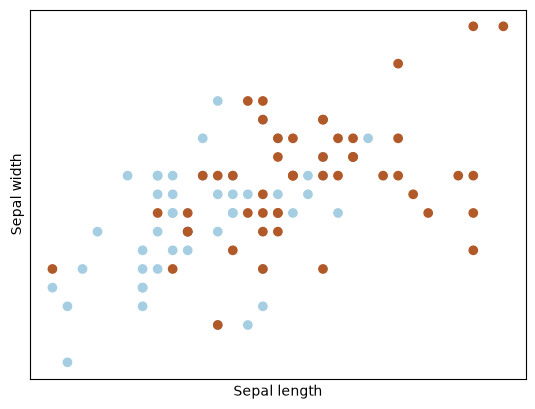

In [13]:
Xh = iris.data[50:150, :2]
Yh = iris.target[50:]
plt.scatter(Xh[:, 0], Xh[:, 1], c=Yh, cmap=plt.cm.Paired)
plt.xlabel('Sepal length'); plt.ylabel('Sepal width')
plt.xticks(()); plt.yticks(()); plt.show()

In [14]:
Xtr, Xte, ytr, yte = train_test_split(Xh, Yh, test_size=0.33, random_state=42)
Xtr = scaler.fit_transform(Xtr)
Xte = scaler.transform(Xte)

qsvc_h = QSVC(quantum_kernel=FidelityQuantumKernel(feature_map=z_feature_map(2, reps=1), fidelity=fidelity))
qsvc_h.fit(Xtr, ytr)
print('Z score:', round(qsvc_h.score(Xte, yte), 3))
print('Z TA test:', round(target_alignment(qsvc_h.quantum_kernel, Xte, yte), 3))

Z score: 0.667
Z TA test: 0.733


## 8. ¿Ayuda entrelazar?

Más entrelazamiento $\neq$ mejor resultado: medidlo (acierto + $TA$) en vez de suponerlo.


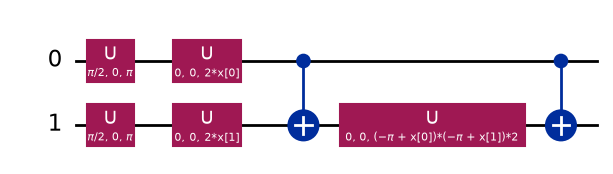

In [15]:
from sklearn.metrics import classification_report
from qiskit.circuit.library import zz_feature_map

fmap_zz = zz_feature_map(2, reps=1)
fmap_zz.decompose().draw('mpl', fold=150)

In [16]:
kernel_zz = FidelityQuantumKernel(feature_map=fmap_zz, fidelity=fidelity)
qsvc_zz = QSVC(quantum_kernel=kernel_zz)
qsvc_zz.fit(Xtr, ytr)
print('ZZ score:', round(qsvc_zz.score(Xte, yte), 3))
print('ZZ TA test:', round(target_alignment(kernel_zz, Xte, yte), 3))
print(classification_report(yte, qsvc_zz.predict(Xte)))

ZZ score: 0.515
ZZ TA test: 0.673
              precision    recall  f1-score   support

           1       0.62      0.42      0.50        19
           2       0.45      0.64      0.53        14

    accuracy                           0.52        33
   macro avg       0.53      0.53      0.51        33
weighted avg       0.55      0.52      0.51        33



## 9. El mismo QSVC en sQUlearn

Misma idea, API sklearn directa: útil cuando el mapa viene de la librería en vez de dibujado a mano.

[sQUlearn](https://squlearn.github.io/index.html)

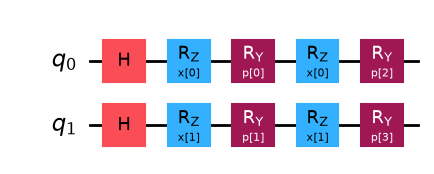

In [17]:
from squlearn.encoding_circuit import HubregtsenEncodingCircuit
from squlearn import Executor
from squlearn.kernel import QSVC as SquQSVC, FidelityKernel

pqc = HubregtsenEncodingCircuit(num_qubits=2, num_features=2, num_layers=2)
pqc.draw('mpl')

In [18]:
qkernel = FidelityKernel(pqc, executor=Executor(), evaluate_duplicates='off_diagonal')
sqsvc = SquQSVC(quantum_kernel=qkernel)
sqsvc.fit(X_train, y_train)
print('sQUlearn QSVC score:', round(sqsvc.score(X_test, y_test), 3))

sQUlearn QSVC score: 1.0


In [19]:
print(classification_report(y_test, sqsvc.predict(X_test)))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        14

    accuracy                           1.00        33
   macro avg       1.00      1.00      1.00        33
weighted avg       1.00      1.00      1.00        33



Por opciones de encoding no será: https://squlearn.github.io/user_guide/encoding_circuits.html

## Para clase

- ¿Por qué el $TA$ puede subir mientras el acierto baja (caso difícil con Z)?
- Tarea: repetid la sección 8 con `reps=2` y con `ProjectedQuantumKernel`. ¿Qué cambia?
